# Task 1: Data Cleaning, Geospatial Wrankling, and Explotation

## 1. Import and merging

In [2]:
# Load necessary libraries for geospatial data processing

import json
import geojson
from functools import partial
import pyproj
import shapely.geometry
import shapely.ops

In [3]:
# Import and merge geospatial data
with open('data/administrative_boundaries/gadm41_BEN_2.geojson') as f:
    benin_data = geojson.load(f)

with open('data/administrative_boundaries/gadm41_TGO_2.geojson') as f:
    togo_data = geojson.load(f)

merged_features = benin_data['features'] + togo_data['features']
merged_data = geojson.FeatureCollection(merged_features)

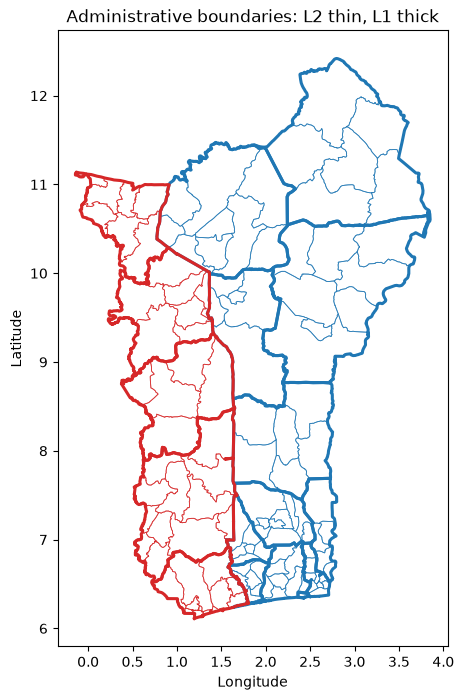

In [4]:
# Basic plot of administrative boundaries (L2 thin, L1 thick, by country)
import matplotlib.pyplot as plt
from shapely.geometry import shape, Polygon, MultiPolygon
from shapely.ops import unary_union

fig, ax = plt.subplots(figsize=(10, 8))

colors = {"BEN": "#1f77b4", "TGO": "#d62728"}
l1_geoms = {}

# 1) Draw level-2 boundaries with thin lines
for feat in merged_data["features"]:
    props = feat["properties"]
    geom = shape(feat["geometry"])

    country = props.get("GID_0", "UNK")
    gid1 = props.get("GID_1")
    c = colors.get(country, "0.5")

    if isinstance(geom, Polygon):
        x, y = geom.exterior.xy
        ax.plot(x, y, color=c, linewidth=0.6, alpha=0.8)
    elif isinstance(geom, MultiPolygon):
        for part in geom.geoms:
            x, y = part.exterior.xy
            ax.plot(x, y, color=c, linewidth=0.6, alpha=0.8)

    l1_geoms.setdefault((country, gid1), []).append(geom)

# 2) Dissolve by level-1 and draw thicker boundaries
for (country, _gid1), geoms in l1_geoms.items():
    c = colors.get(country, "0.5")
    geom_l1 = unary_union(geoms)

    if isinstance(geom_l1, Polygon):
        x, y = geom_l1.exterior.xy
        ax.plot(x, y, color=c, linewidth=2.2)
    elif isinstance(geom_l1, MultiPolygon):
        for part in geom_l1.geoms:
            x, y = part.exterior.xy
            ax.plot(x, y, color=c, linewidth=2.2)

ax.set_aspect("equal")
ax.set_title("Administrative boundaries: L2 thin, L1 thick")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

### Short Description and Peculiarities

This map shows administrative boundaries for Benin (blue) and Togo (red). Thin lines represent second-level divisions, while thicker lines represent first-level divisions, which makes both levels visible at the same time.

A notable peculiarity is the much denser subdivision in southern Benin, where many small units are clustered near the coast. 

## 2. Importing maize  yield

In [5]:
import pandas as pd

maize_yield = pd.read_csv("data/administrative_yield/fews_net_yield_TGO_BEN.csv", encoding='utf-8')
print(maize_yield.columns)


Index(['country', 'admin_1', 'admin_2', 'year', 'season_name', 'season_type',
       'value', 'unit', 'product'],
      dtype='str')


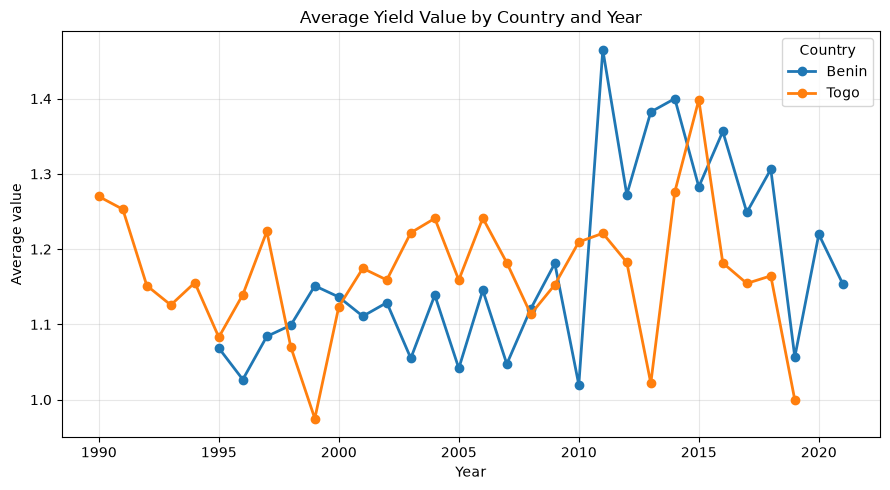

In [6]:
# Basic investigation plot: yearly average value by country
import matplotlib.pyplot as plt

plot_df = maize_yield.copy()
plot_df["year"] = pd.to_numeric(plot_df["year"], errors="coerce")
plot_df["value"] = pd.to_numeric(plot_df["value"], errors="coerce")
plot_df = plot_df.dropna(subset=["year", "value", "country"])

year_country = (
    plot_df.groupby(["year", "country"], as_index=False)["value"]
    .mean()
    .sort_values(["country", "year"])
)

fig, ax = plt.subplots(figsize=(9, 5))
for country, g in year_country.groupby("country"):
    ax.plot(g["year"], g["value"], marker="o", linewidth=2, label=country)

ax.set_title("Average Yield Value by Country and Year")
ax.set_xlabel("Year")
ax.set_ylabel("Average value")
ax.legend(title="Country")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A look at the CSV file and this graph reveals data on maize production—broken down by country, as well as by department and municipality-from 1990 to 2021.
The graph shows production levels in each country, fluctuating between 1 and 1.4 MT/ha depending on the year. In 2011, Benin experienced a peak of around 1.47 MT/ha, followed by a drop of approximately 0.2 MT/ha the following year. A similar pattern occurred in Togo between 2015 and 2016.

## 3. Import MODIS VI data

In [9]:
import xarray as xr

# Here I used AI to assist in loading and inspecting the MODIS vegetation indices dataset

ds = xr.open_dataset(
    "data/modis_vegetation_indices/modis_vi.nc",
    engine="h5netcdf",
    decode_cf=False
)
print(ds)

<xarray.Dataset> Size: 11MB
Dimensions:      (time: 264, band: 1, y: 127, x: 81)
Coordinates:
  * time         (time) int64 2kB 0 31 62 92 123 ... 7885 7914 7945 7975 8006
  * band         (band) int64 8B 1
  * y            (y) float64 1kB 12.42 12.37 12.32 12.27 ... 6.225 6.175 6.125
  * x            (x) float64 648B -0.125 -0.075 -0.025 ... 3.775 3.825 3.875
Data variables:
    spatial_ref  int64 8B ...
    NDVI         (time, band, y, x) int16 5MB ...
    EVI          (time, band, y, x) int16 5MB ...
Attributes: (12/177)
    ALGORITHMPACKAGEACCEPTANCEDATE:      102004
    ALGORITHMPACKAGEMATURITYCODE:        Normal
    ALGORITHMPACKAGENAME:                MOD_PR13C2
    ALGORITHMPACKAGEVERSION:             5
    ASSOCIATEDINSTRUMENTSHORTNAME.1:     MODIS
    ASSOCIATEDPLATFORMSHORTNAME.1:       Aqua
    ...                                  ...
    SNOWICEFLAGGED:                      YES
    SOUTHBOUNDINGCOORDINATE:             -90.0
    SPSOPARAMETERS:                      2749, 43

In [10]:
# Raw arrays
ndvi_raw = ds["NDVI"]
evi_raw = ds["EVI"]

# Metadata
scale = float(ndvi_raw.attrs.get("scale_factor", 10000.0))
offset = float(ndvi_raw.attrs.get("add_offset", 0.0))
fill_raw = float(ndvi_raw.attrs.get("_FillValue", -3000))

# Correct scaling direction
if scale > 1:
    ndvi = ndvi_raw / scale + offset
    evi = evi_raw / scale + offset
    fill_scaled = fill_raw / scale + offset
else:
    ndvi = ndvi_raw * scale + offset
    evi = evi_raw * scale + offset
    fill_scaled = fill_raw * scale + offset

# Mask invalid values
ndvi = ndvi.where(ndvi != fill_scaled)
evi = evi.where(evi != fill_scaled)


In [11]:
import numpy as np
import pandas as pd
import xarray as xr
from shapely.geometry import shape
from shapely import contains_xy

# If NDVI/EVI still have a "band" dimension, keep only the first band.
# This simplifies the arrays to (time, y, x).
if "band" in ndvi.dims:
    ndvi = ndvi.isel(band=0, drop=True)
if "band" in evi.dims:
    evi = evi.isel(band=0, drop=True)

# Read grid coordinates from the raster dataset.
x = ds["x"].values
y = ds["y"].values

# Build full 2D coordinate grids used for point-in-polygon masking.
xx, yy = np.meshgrid(x, y)

# Decode the time coordinate using CF metadata if possible.
# Fallback: interpret time as "days since 2002-07-01".
try:
    t = pd.to_datetime(xr.decode_cf(ds[["time"]])["time"].values)
except Exception:
    t = pd.to_datetime(ds["time"].values, unit="D", origin="2002-07-01")

# Store all output rows here, then convert to DataFrame at the end.
rows = []

# Loop over each admin2 polygon feature.
for feat in merged_data["features"]:
    # Geometry for spatial masking.
    geom = shape(feat["geometry"])
    # Attribute dictionary (country/admin names).
    p = feat["properties"]

    # Create a boolean mask: True for raster pixels inside the polygon.
    mask = contains_xy(geom, xx, yy)
    mask_da = xr.DataArray(
        mask,
        coords={"y": ds["y"], "x": ds["x"]},
        dims=("y", "x")
    )

    # Keep NDVI/EVI values only inside this polygon.
    ndvi_poly = ndvi.where(mask_da)
    evi_poly = evi.where(mask_da)

    # Compute NDVI summary stats for each time step.
    ndvi_mean = ndvi_poly.mean(dim=("y", "x"), skipna=True).values
    ndvi_min  = ndvi_poly.min(dim=("y", "x"), skipna=True).values
    ndvi_max  = ndvi_poly.max(dim=("y", "x"), skipna=True).values

    # Compute EVI summary stats for each time step.
    evi_mean = evi_poly.mean(dim=("y", "x"), skipna=True).values
    evi_min  = evi_poly.min(dim=("y", "x"), skipna=True).values
    evi_max  = evi_poly.max(dim=("y", "x"), skipna=True).values

    # Write one NDVI row and one EVI row for each date.
    for i in range(len(t)):
        rows.append({
            "country": p.get("GID_0"),   # Country code (BEN/TGO)
            "admin_1": p.get("NAME_1"),  # Admin level 1 name
            "admin_2": p.get("NAME_2"),  # Admin level 2 name
            "year": t[i].year,           # Year from decoded time
            "month": t[i].month,         # Month from decoded time
            "index": "NDVI",             # Vegetation index type
            "mean": ndvi_mean[i],        # Mean NDVI in polygon
            "min": ndvi_min[i],          # Min NDVI in polygon
            "max": ndvi_max[i],          # Max NDVI in polygon
        })
        rows.append({
            "country": p.get("GID_0"),
            "admin_1": p.get("NAME_1"),
            "admin_2": p.get("NAME_2"),
            "year": t[i].year,
            "month": t[i].month,
            "index": "EVI",
            "mean": evi_mean[i],         # Mean EVI in polygon
            "min": evi_min[i],           # Min EVI in polygon
            "max": evi_max[i],           # Max EVI in polygon
        })

# Convert collected rows to a tidy table.
stats_admin2 = pd.DataFrame(rows)

# Quick check: number of rows and first records.
print(stats_admin2.shape)
stats_admin2.head()

(62304, 9)


,country,admin_1,admin_2,year,month,index,mean,min,max
0,BEN,Alibori,Banikoara,2002,7,NDVI,0.556722,0.3668,0.7109
1,BEN,Alibori,Banikoara,2002,7,EVI,0.378289,0.2526,0.4703
2,BEN,Alibori,Banikoara,2002,8,NDVI,0.721632,0.5818,0.7814
3,BEN,Alibori,Banikoara,2002,8,EVI,0.501901,0.3877,0.5723
4,BEN,Alibori,Banikoara,2002,9,NDVI,0.715412,0.6626,0.7749


Rows in filtered VI table: 118
Matched admin2 values ready for mapping: 118


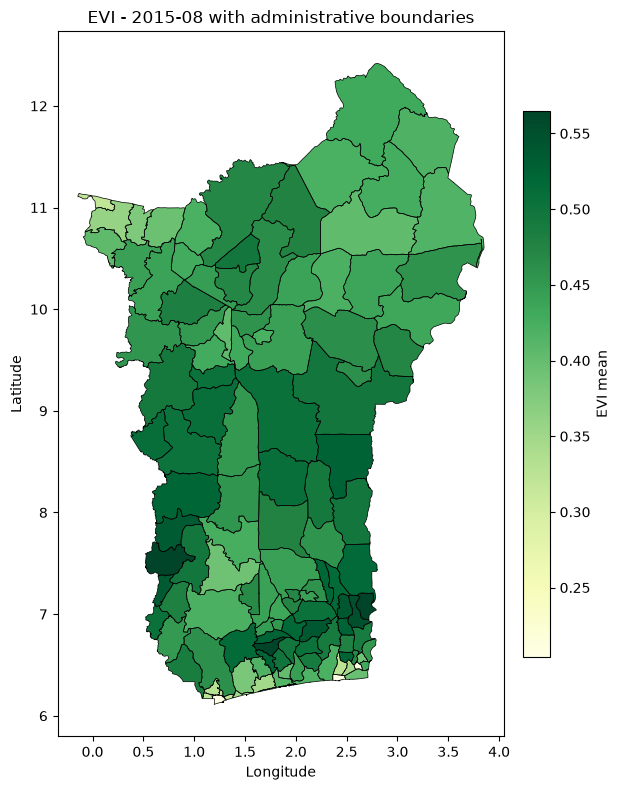

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import unicodedata
from shapely.geometry import shape, Polygon, MultiPolygon
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

# -----------------------------
# Choose what to display
# -----------------------------
index_name = "EVI"   # "NDVI" or "EVI"
year_sel = 2015
month_sel = 8

# -----------------------------
# Helper to normalize text keys
# -----------------------------
def clean_text(value):
    # Convert to lowercase, remove spaces and accents for safer matching
    text = str(value).strip().lower()
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", errors="ignore").decode("utf-8")
    return text

# -----------------------------
# 1) Keep only one index + one date
# -----------------------------
vi = stats_admin2.copy()
vi["year"] = pd.to_numeric(vi["year"], errors="coerce")
vi["month"] = pd.to_numeric(vi["month"], errors="coerce")
vi["mean"] = pd.to_numeric(vi["mean"], errors="coerce")

vi = vi[
    (vi["index"] == index_name) &
    (vi["year"] == year_sel) &
    (vi["month"] == month_sel)
].dropna(subset=["country", "admin_1", "admin_2", "mean"])

# Standardize country naming to match GADM properties
vi["country"] = vi["country"].replace({
    "BEN": "BEN", "TGO": "TGO",
    "Benin": "BEN", "Togo": "TGO"
})

print("Rows in filtered VI table:", len(vi))

# Stop early if there is no data for this month/year
if vi.empty:
    raise ValueError(
        f"No data found for {index_name} in {year_sel}-{month_sel:02d}. "
        "Try another month/year that exists in stats_admin2."
    )

# Build a lookup: (country, admin_1, admin_2) -> mean value
value_by_admin = {}
for _, row in vi.iterrows():
    key = (
        clean_text(row["country"]),
        clean_text(row["admin_1"]),
        clean_text(row["admin_2"])
    )
    value_by_admin[key] = row["mean"]

print("Matched admin2 values ready for mapping:", len(value_by_admin))

# -----------------------------
# 2) Convert polygons into patches
# -----------------------------
patches = []
patch_values = []
boundary_lines = []

for feat in merged_data["features"]:
    props = feat["properties"]
    geom = shape(feat["geometry"])

    # Build key from boundary file attributes
    key = (
        clean_text(props.get("GID_0", "")),
        clean_text(props.get("NAME_1", "")),
        clean_text(props.get("NAME_2", ""))
    )
    val = value_by_admin.get(key, np.nan)

    # Add one patch per polygon part
    if isinstance(geom, Polygon):
        coords = np.asarray(geom.exterior.coords)
        patches.append(MplPolygon(coords, closed=True))
        patch_values.append(val)
        bx, by = geom.exterior.xy
        boundary_lines.append((bx, by))

    elif isinstance(geom, MultiPolygon):
        for part in geom.geoms:
            coords = np.asarray(part.exterior.coords)
            patches.append(MplPolygon(coords, closed=True))
            patch_values.append(val)
            bx, by = part.exterior.xy
            boundary_lines.append((bx, by))

patch_values = np.asarray(patch_values, dtype=float)

# -----------------------------
# 3) Draw the map
# -----------------------------
fig, ax = plt.subplots(figsize=(10, 8))

# Compute color limits from valid values only
valid = np.isfinite(patch_values)
if valid.any():
    vmin = np.nanpercentile(patch_values[valid], 2)
    vmax = np.nanpercentile(patch_values[valid], 98)
else:
    vmin, vmax = 0.0, 1.0

norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
cmap = mpl.cm.YlGn.copy()
cmap.set_bad(color="white")  # Areas with missing data stay white

poly_collection = PatchCollection(
    patches,
    cmap=cmap,
    norm=norm,
    linewidth=0
)
poly_collection.set_array(patch_values)
poly_collection.set_edgecolor("none")
ax.add_collection(poly_collection)

# Overlay administrative boundaries
for bx, by in boundary_lines:
    ax.plot(bx, by, color="black", linewidth=0.5)

# Add colorbar
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label(f"{index_name} mean")

# Final layout
ax.set_title(f"{index_name} - {year_sel}-{month_sel:02d} with administrative boundaries")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Analysis:
Based on visual inspection alone, there is some useful spatial signal, but not enough to claim that vegetation fully explains maize yield.
Across polygons, yes, there is clear variation: some areas are consistently greener than others.
Within polygons, not really: each polygon is mapped with a single aggregated value, so internal heterogeneity is hidden. That means I cannot judge field-level or sub-district variability from this map alone.

### For level 1

In [15]:
import pandas as pd

# Build level-1 table from level-2 stats
stats_admin1 = (
    stats_admin2
    .groupby(["country", "admin_1", "year", "month", "index"], as_index=False)
    .agg(
        mean=("mean", "mean"),
        min=("min", "min"),
        max=("max", "max")
    )
)

print(stats_admin1.shape)
stats_admin1.head()

(8976, 8)


,country,admin_1,year,month,index,mean,min,max
0,BEN,Alibori,2002,7,EVI,0.402454,0.2304,0.5357
1,BEN,Alibori,2002,7,NDVI,0.587926,0.3175,0.7346
2,BEN,Alibori,2002,8,EVI,0.493640,0.2934,0.6108
3,BEN,Alibori,2002,8,NDVI,0.726310,0.4107,0.8140
4,BEN,Alibori,2002,9,EVI,0.491098,0.3053,0.5645


In [16]:
from shapely.geometry import shape
from shapely.ops import unary_union

# Build dissolved level-1 geometries
l1_parts = {}
for feat in merged_data["features"]:
    p = feat["properties"]
    key = (p.get("GID_0"), p.get("GID_1"), p.get("NAME_1"))
    l1_parts.setdefault(key, []).append(shape(feat["geometry"]))

l1_geoms = []
for (gid0, gid1, name1), geoms in l1_parts.items():
    l1_geoms.append({
        "country": gid0,      # BEN/TGO
        "gid1": gid1,         # Level-1 code
        "admin_1": name1,     # Level-1 name
        "geometry": unary_union(geoms)
    })

print("Number of level-1 polygons:", len(l1_geoms))

Number of level-1 polygons: 17


Matched level-1 values: 17


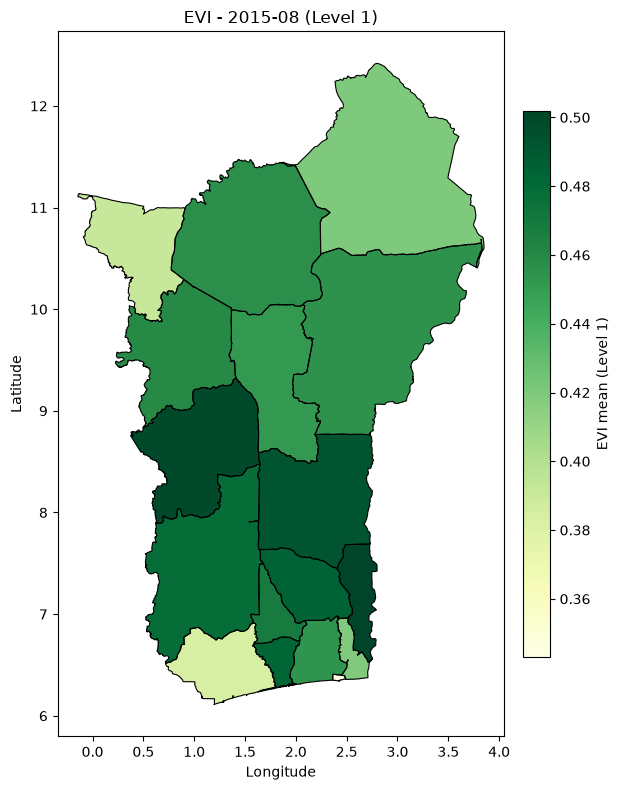

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import unicodedata
from shapely.geometry import Polygon, MultiPolygon
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

# Parameters
index_name = "EVI"   # NDVI or EVI
year_sel = 2015
month_sel = 8

def clean_text(v):
    t = str(v).strip().lower()
    t = unicodedata.normalize("NFKD", t)
    return t.encode("ascii", errors="ignore").decode("utf-8")

# Filter level-1 stats
vi1 = stats_admin1.copy()
vi1["year"] = pd.to_numeric(vi1["year"], errors="coerce")
vi1["month"] = pd.to_numeric(vi1["month"], errors="coerce")
vi1["mean"] = pd.to_numeric(vi1["mean"], errors="coerce")

vi1 = vi1[
    (vi1["index"] == index_name) &
    (vi1["year"] == year_sel) &
    (vi1["month"] == month_sel)
].dropna(subset=["country", "admin_1", "mean"])

vi1["country"] = vi1["country"].replace({
    "Benin": "BEN", "Togo": "TGO",
    "BEN": "BEN", "TGO": "TGO"
})

# Lookup (country, admin_1) -> mean
val_map = {}
for _, r in vi1.iterrows():
    key = (clean_text(r["country"]), clean_text(r["admin_1"]))
    val_map[key] = r["mean"]

print("Matched level-1 values:", len(val_map))

# Build patches
patches, values, boundaries = [], [], []

for rec in l1_geoms:
    g = rec["geometry"]
    key = (clean_text(rec["country"]), clean_text(rec["admin_1"]))
    v = val_map.get(key, np.nan)

    if isinstance(g, Polygon):
        coords = np.asarray(g.exterior.coords)
        patches.append(MplPolygon(coords, closed=True))
        values.append(v)
        bx, by = g.exterior.xy
        boundaries.append((bx, by))
    elif isinstance(g, MultiPolygon):
        for part in g.geoms:
            coords = np.asarray(part.exterior.coords)
            patches.append(MplPolygon(coords, closed=True))
            values.append(v)
            bx, by = part.exterior.xy
            boundaries.append((bx, by))

values = np.asarray(values, dtype=float)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

valid = np.isfinite(values)
if valid.any():
    vmin = np.nanpercentile(values[valid], 2)
    vmax = np.nanpercentile(values[valid], 98)
else:
    vmin, vmax = 0.0, 1.0

norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
cmap = mpl.cm.YlGn.copy()
cmap.set_bad(color="white")

pc = PatchCollection(patches, cmap=cmap, norm=norm, linewidth=0)
pc.set_array(values)
pc.set_edgecolor("none")
ax.add_collection(pc)

# Overlay boundaries (level 1)
for bx, by in boundaries:
    ax.plot(bx, by, color="black", linewidth=0.8)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label(f"{index_name} mean (Level 1)")

ax.set_title(f"{index_name} - {year_sel}-{month_sel:02d} (Level 1)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

The answer does change between Level 1 and Level 2.
At Level 2, you see more local contrast, so it is better for spotting potential links with yield differences.
At Level 1, aggregation smooths those differences, which reduces noise but can also mask meaningful local patterns. So Level 1 is better for broad regional interpretation, while Level 2 is better for exploring yield-related spatial variation.
In short: promising visual evidence, but not sufficient by itself without a quantitative test.

## 4. Reshaping extracted data into a wide format

In [18]:
import numpy as np
import pandas as pd
import unicodedata

# small utility for reliable joins across sources
def normalize_text(x):
    s = str(x).strip().lower()
    s = unicodedata.normalize("NFKD", s)
    return s.encode("ascii", errors="ignore").decode("utf-8")

# -----------------------------
# Build wide vegetation features
# -----------------------------
vi = stats_admin2.copy()

vi["country"] = vi["country"].replace({"Benin": "BEN", "Togo": "TGO"})
vi["year"] = pd.to_numeric(vi["year"], errors="coerce")
vi["month"] = pd.to_numeric(vi["month"], errors="coerce")
vi["mean"] = pd.to_numeric(vi["mean"], errors="coerce")
vi["min"] = pd.to_numeric(vi["min"], errors="coerce")
vi["max"] = pd.to_numeric(vi["max"], errors="coerce")

vi = vi.dropna(subset=["country", "admin_1", "admin_2", "year", "month", "index"])

vi["country_key"] = vi["country"].map(normalize_text)
vi["admin1_key"] = vi["admin_1"].map(normalize_text)
vi["admin2_key"] = vi["admin_2"].map(normalize_text)
vi["year"] = vi["year"].astype(int)
vi["month"] = vi["month"].astype(int)

# long format for stats first, then pivot once
vi_long = vi.melt(
    id_vars=["country_key", "admin1_key", "admin2_key", "year", "month", "index"],
    value_vars=["mean", "min", "max"],
    var_name="stat",
    value_name="value"
)

vi_long["feature"] = (
    vi_long["index"].str.lower() + "_" +
    vi_long["stat"].str.lower() + "_" +
    vi_long["month"].astype(str).str.zfill(2)
)

vi_wide = (
    vi_long
    .pivot_table(
        index=["country_key", "admin1_key", "admin2_key", "year"],
        columns="feature",
        values="value",
        aggfunc="mean"
    )
    .reset_index()
)

# enforce a stable 72-feature layout
expected_features = [
    f"{idx}_{st}_{m:02d}"
    for idx in ["ndvi", "evi"]
    for st in ["mean", "min", "max"]
    for m in range(1, 13)
]

for col in expected_features:
    if col not in vi_wide.columns:
        vi_wide[col] = np.nan

vi_wide = vi_wide[["country_key", "admin1_key", "admin2_key", "year"] + expected_features]

print("VI wide shape:", vi_wide.shape)
print("Number of VI features:", len(expected_features))

# -----------------------------
# Prepare yield table
# -----------------------------
y = maize_yield.copy()
y["country"] = y["country"].replace({"Benin": "BEN", "Togo": "TGO"})
y["year"] = pd.to_numeric(y["year"], errors="coerce")
y["value"] = pd.to_numeric(y["value"], errors="coerce")

y = y.dropna(subset=["country", "admin_1", "admin_2", "year", "value"])
y["year"] = y["year"].astype(int)

if "product" in y.columns:
    y = y[y["product"].astype(str).str.lower().str.contains("maize", na=False)]

y["country_key"] = y["country"].map(normalize_text)
y["admin1_key"] = y["admin_1"].map(normalize_text)
y["admin2_key"] = y["admin_2"].map(normalize_text)

key_cols = ["country_key", "admin1_key", "admin2_key", "year"]

# reduce to one yield row per key
y_one_row = (
    y.groupby(key_cols, as_index=False)
     .agg(
         yield_value=("value", "mean"),
         unit=("unit", "first"),
         season_name=("season_name", "first"),
         season_type=("season_type", "first"),
         product=("product", "first")
     )
)

# -----------------------------
# Merge and inspect
# -----------------------------
merged = y_one_row.merge(
    vi_wide,
    on=key_cols,
    how="left",
    validate="1:1"
)

missing_vi = merged[expected_features].isna().all(axis=1)

print("Merged shape:", merged.shape)
print("Rows with VI match:", int((~missing_vi).sum()))
print("Rows without VI match:", int(missing_vi.sum()))

# optional dataset for modeling only
merged_model = merged.loc[~missing_vi].copy()
print("Model-ready shape:", merged_model.shape)

merged.head()

VI wide shape: (2714, 76)
Number of VI features: 72
Merged shape: (2869, 81)
Rows with VI match: 1997
Rows without VI match: 872
Model-ready shape: (1997, 81)


,country_key,admin1_key,admin2_key,year,yield_value,unit,season_name,season_type,product,ndvi_mean_01,...,evi_max_03,evi_max_04,evi_max_05,evi_max_06,evi_max_07,evi_max_08,evi_max_09,evi_max_10,evi_max_11,evi_max_12
0,ben,alibori,banikoara,1999,1.207422,MT/ha,Main,Harvest,Maize (Corn),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ben,alibori,banikoara,2000,1.103059,MT/ha,Main,Harvest,Maize (Corn),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ben,alibori,banikoara,2001,1.178110,MT/ha,Main,Harvest,Maize (Corn),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ben,alibori,banikoara,2002,1.194343,MT/ha,Main,Harvest,Maize (Corn),NaN,...,NaN,NaN,NaN,NaN,0.4703,0.5723,0.5645,0.4880,0.3210,0.2313
4,ben,alibori,banikoara,2003,1.468042,MT/ha,Main,Harvest,Maize (Corn),0.297684,...,0.1802,0.2624,0.3254,0.4521,0.5308,0.5845,0.5563,0.4486,0.3515,0.2230


I reshaped the extracted vegetation-index table into a feature matrix with one row per unique country, admin level 1, admin level 2, and year.
For each row, I generated 72 monthly VI features:

2 indices: NDVI, EVI
3 statistics: mean, min, max
12 months: 01 to 12
Feature names follow a consistent naming scheme such as ndvi_mean_01, ndvi_max_09, evi_min_12.

I then merged these vegetation features with the maize yield table using country, admin_1, admin_2, and year.
During merging, I handled three common inconsistencies:

1. Name formatting mismatch
Administrative names were not always written the same way across sources. I normalized text (lowercase, trimmed spaces, accent removal) and standardized country labels before joining.
2. Duplicate yield rows for the same location-year
Some yield records shared the same merge key due to seasonal records. I aggregated them to a single value per key using the mean yield.
3. Uneven temporal coverage
MODIS-based VI data do not fully overlap all yield years and may miss some month-location combinations. I preserved all 72 columns and left missing values as NaN rather than imputing unsupported values.
As a result, the merged table is analysis-ready and transparent about data gaps.

# Task 2: Modeling and results interpretation

## 1. Comparing the distribution of yields to a log transformation of yielgs

   metric        yield    log_yield
0   count  2869.000000  2869.000000
1    mean     1.171864     0.098623
2  median     1.096562     0.092180
3     std     0.426125     0.359109
4    skew     3.000983    -1.155438


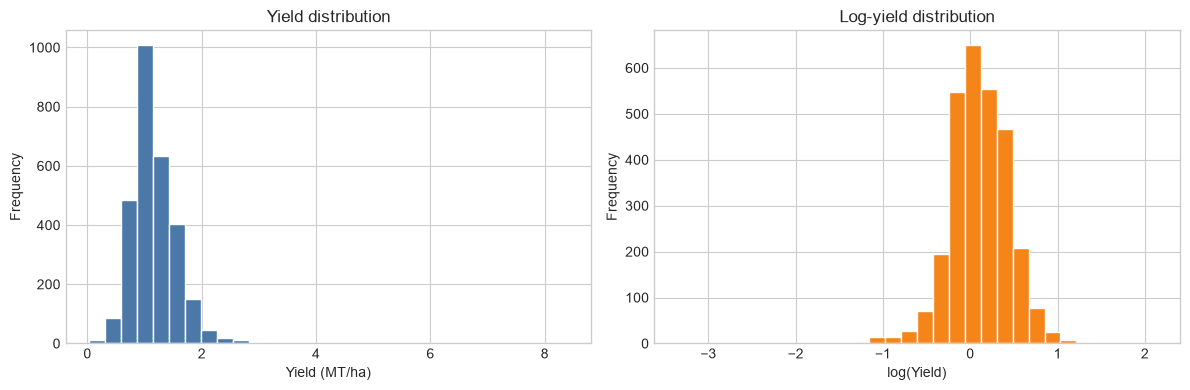

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pick the model table created in Task 1
# fallback to merged if merged_model is not available
data_for_target = merged.copy()

# extract the target variable for modeling
y = pd.to_numeric(data_for_target["yield_value"], errors="coerce").dropna()

# log is only valid for strictly positive values
y_pos = y[y > 0].copy()

if len(y_pos) < len(y):
    print(f"Dropped {len(y) - len(y_pos)} non-positive yield values before log transform.")

log_y = np.log(y_pos)

# quick numeric comparison
summary = pd.DataFrame({
    "metric": ["count", "mean", "median", "std", "skew"],
    "yield": [
        y_pos.shape[0],
        y_pos.mean(),
        y_pos.median(),
        y_pos.std(),
        y_pos.skew()
    ],
    "log_yield": [
        log_y.shape[0],
        log_y.mean(),
        log_y.median(),
        log_y.std(),
        pd.Series(log_y).skew()
    ]
})

print(summary)

# side-by-side visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_pos, bins=30, color="#4C78A8", edgecolor="white")
axes[0].set_title("Yield distribution")
axes[0].set_xlabel("Yield (MT/ha)")
axes[0].set_ylabel("Frequency")

axes[1].hist(log_y, bins=30, color="#F58518", edgecolor="white")
axes[1].set_title("Log-yield distribution")
axes[1].set_xlabel("log(Yield)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()



I will model log(yield) rather than raw yield because it reduces right-skewness and improves variance stability, which generally leads to better-behaved regression errors and more reliable out-of-sample performance.

In [20]:
# final target choice for modeling
target_col = "log_yield"
model_df = data_for_target.loc[y_pos.index].copy()
model_df[target_col] = np.log(model_df["yield_value"])

print("Chosen modeling target:", target_col)
print("Rows available for modeling:", model_df.shape[0])

Chosen modeling target: log_yield
Rows available for modeling: 1997


## 2. Encoding the location (admin2), split dataset, train ridge, regression, creoss -validated predictive model

In [32]:
import os
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# Set seeds for reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Start from the table prepared in Task 1
work = model_df.copy()

# Keep VI predictors + location key + target
vi_cols = [c for c in work.columns if c.startswith("ndvi_") or c.startswith("evi_")]
keep_cols = vi_cols + ["admin2_key", "log_yield"]
work = work[keep_cols].dropna(subset=["log_yield"]).copy()

# Define feature matrix and target vector
X = work[vi_cols + ["admin2_key"]]
print(X.head())
y = work["log_yield"]

# Create 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# Build preprocessing:
# - numeric VI columns: median imputation + scaling
# - admin2 location: one-hot encoding
prep = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), vi_cols),
        ("loc", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), ["admin2_key"])
    ]
)

# Ridge model wrapped in a pipeline
pipe = Pipeline(steps=[
    ("prep", prep),
    ("model", Ridge())
])

# Tune alpha with cross-validation on the training split
param_grid = {"model__alpha": np.logspace(-3, 3, 13)}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

# Validation score from CV (mean across folds)
val_r2 = search.best_score_

# Final test score on untouched hold-out set
y_pred_test = search.predict(X_test)
test_r2 = r2_score(y_test, y_pred_test)

print(f"Best alpha: {search.best_params_['model__alpha']}")
print(f"Validation R² (CV mean): {val_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")
print(f"Gap (test - validation): {test_r2 - val_r2:+.4f}")

   ndvi_mean_01  ndvi_mean_02  ndvi_mean_03  ndvi_mean_04  ndvi_mean_05  \
3           NaN           NaN           NaN           NaN           NaN   
4      0.297684      0.273734      0.255742      0.330161      0.385267   
5      0.296818      0.266949      0.260846      0.295339      0.370009   
6      0.267420      0.246872      0.237502      0.262834      0.342534   
7      0.291396      0.270054      0.262745      0.270172      0.300586   

   ndvi_mean_06  ndvi_mean_07  ndvi_mean_08  ndvi_mean_09  ndvi_mean_10  ...  \
3           NaN      0.556722      0.721632      0.715412      0.649849  ...   
4      0.531774      0.661924      0.727101      0.721169      0.602213  ...   
5      0.509186      0.633303      0.701639      0.719770      0.600513  ...   
6      0.478615      0.619702      0.705550      0.708330      0.642916  ...   
7      0.398340      0.531874      0.677535      0.704076      0.679497  ...   

   evi_max_04  evi_max_05  evi_max_06  evi_max_07  evi_max_08  evi_m

The validation (R²) (0.3408) and test (R²) (0.3338) are very close, with a small gap of (-0.0070).
This means the model’s performance is stable from cross-validation to truly unseen data, so there is no strong sign of overfitting.
In practice, the validation score is used during model tuning (to choose hyperparameters like alpha), while the test score is the final unbiased estimate of generalization.
Since both numbers are aligned, I can trust that the model should behave similarly on new data from the same distribution.
At the same time, an (R²) around 0.33 indicates that the model captures a meaningful part of yield variability, but a large share remains unexplained by the current predictors, which suggests room for improvement with additional agronomic or climate variables.

## 3. Admin1 aggregation, retrain, and comparison with the previous model

In this section, I aggregate yield and vegetation predictors at admin1 level, then rerun the same train/validation-test workflow with one-hot encoding for admin1. I'll finally compare validation and test performance against the previous admin2 model and discuss likely reasons.

In [25]:
import os
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# Keep all random generators fixed for reproducibility.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Start from the modeling table built above (contains log_yield and VI columns).
base = model_df.copy()

# Keep only columns needed for this section.
vi_cols = sorted([c for c in base.columns if c.startswith("ndvi_") or c.startswith("evi_")])
core_cols = ["country_key", "admin1_key", "year", "log_yield"] + vi_cols
admin1_raw = base[core_cols].copy()

# Aggregate to admin1-year using means for both target and predictors.
admin1_df = (
    admin1_raw
    .groupby(["country_key", "admin1_key", "year"], as_index=False)
    .mean(numeric_only=True)
)

# Build feature matrix and target.
X_admin1 = admin1_df[vi_cols + ["admin1_key"]].copy()
y_admin1 = admin1_df["log_yield"].copy()

# Use the same split policy as before.
X_train, X_test, y_train, y_test = train_test_split(
    X_admin1,
    y_admin1,
    test_size=0.20,
    random_state=SEED
)

# Numeric VI preprocessing and one-hot admin1 encoding.
prep = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            vi_cols
        ),
        (
            "loc",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            ["admin1_key"]
        )
    ]
)

# Ridge model with cross-validated alpha tuning.
pipe = Pipeline(steps=[
    ("prep", prep),
    ("model", Ridge())
])

param_grid = {"model__alpha": np.logspace(-3, 3, 13)}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

# Validation score is CV mean; test score is hold-out performance.
admin1_val_r2 = search.best_score_
admin1_test_r2 = r2_score(y_test, search.predict(X_test))
admin1_gap = admin1_test_r2 - admin1_val_r2
admin1_best_alpha = float(search.best_params_["model__alpha"])

# Previous model scores from admin2 section (already computed above).
admin2_val_r2 = float(val_r2)
admin2_test_r2 = float(test_r2)
admin2_gap = admin2_test_r2 - admin2_val_r2
admin2_best_alpha = float(globals().get("best_alpha", np.nan))

# Build a compact comparison table.
comparison = pd.DataFrame([
    {
        "model": "Admin2 + one-hot admin2",
        "best_alpha": admin2_best_alpha,
        "validation_r2": admin2_val_r2,
        "test_r2": admin2_test_r2,
        "gap_test_minus_val": admin2_gap
    },
    {
        "model": "Admin1 aggregate + one-hot admin1",
        "best_alpha": admin1_best_alpha,
        "validation_r2": float(admin1_val_r2),
        "test_r2": float(admin1_test_r2),
        "gap_test_minus_val": float(admin1_gap)
    }
])

# Print interpretation helpers.
print("Admin1 best alpha:", admin1_best_alpha)
print(f"Admin1 validation R2: {admin1_val_r2:.4f}")
print(f"Admin1 test R2:       {admin1_test_r2:.4f}")
print(f"Admin1 gap:           {admin1_gap:+.4f}")

if admin1_test_r2 > admin2_test_r2:
    print("\nBetter test performance: Admin1 aggregate model")
else:
    print("\nBetter test performance: Admin2 model")

comparison

Admin1 best alpha: 10.0
Admin1 validation R2: 0.2718
Admin1 test R2:       0.3658
Admin1 gap:           +0.0941

Better test performance: Admin1 aggregate model


,model,best_alpha,validation_r2,test_r2,gap_test_minus_val
0,Admin2 + one-hot admin2,NaN,0.340811,0.333769,-0.007042
1,Admin1 aggregate + one-hot admin1,10.0,0.271759,0.365817,0.094058


### Interpretation and comparison

The admin1 model has a better test R² (0.3658) than the admin2 model (0.3338), but a lower validation R² (0.2718 vs 0.3408).
So, admin1 looks better on this test split, while cross-validation suggests weaker average performance.

A likely reason is aggregation: at admin1 level, noise is reduced, which can help prediction, but you also lose local detail and some sample size, which can hurt CV results.

Because the admin1 test-validation gap is large (+0.0941), this split may be easier than typical folds, so results should be read with caution.

To improve: use repeated/nested CV, add weather and soil variables, include temporal features, try other models, and use spatially grouped validation.

### 4. Publication-quality scatter plot

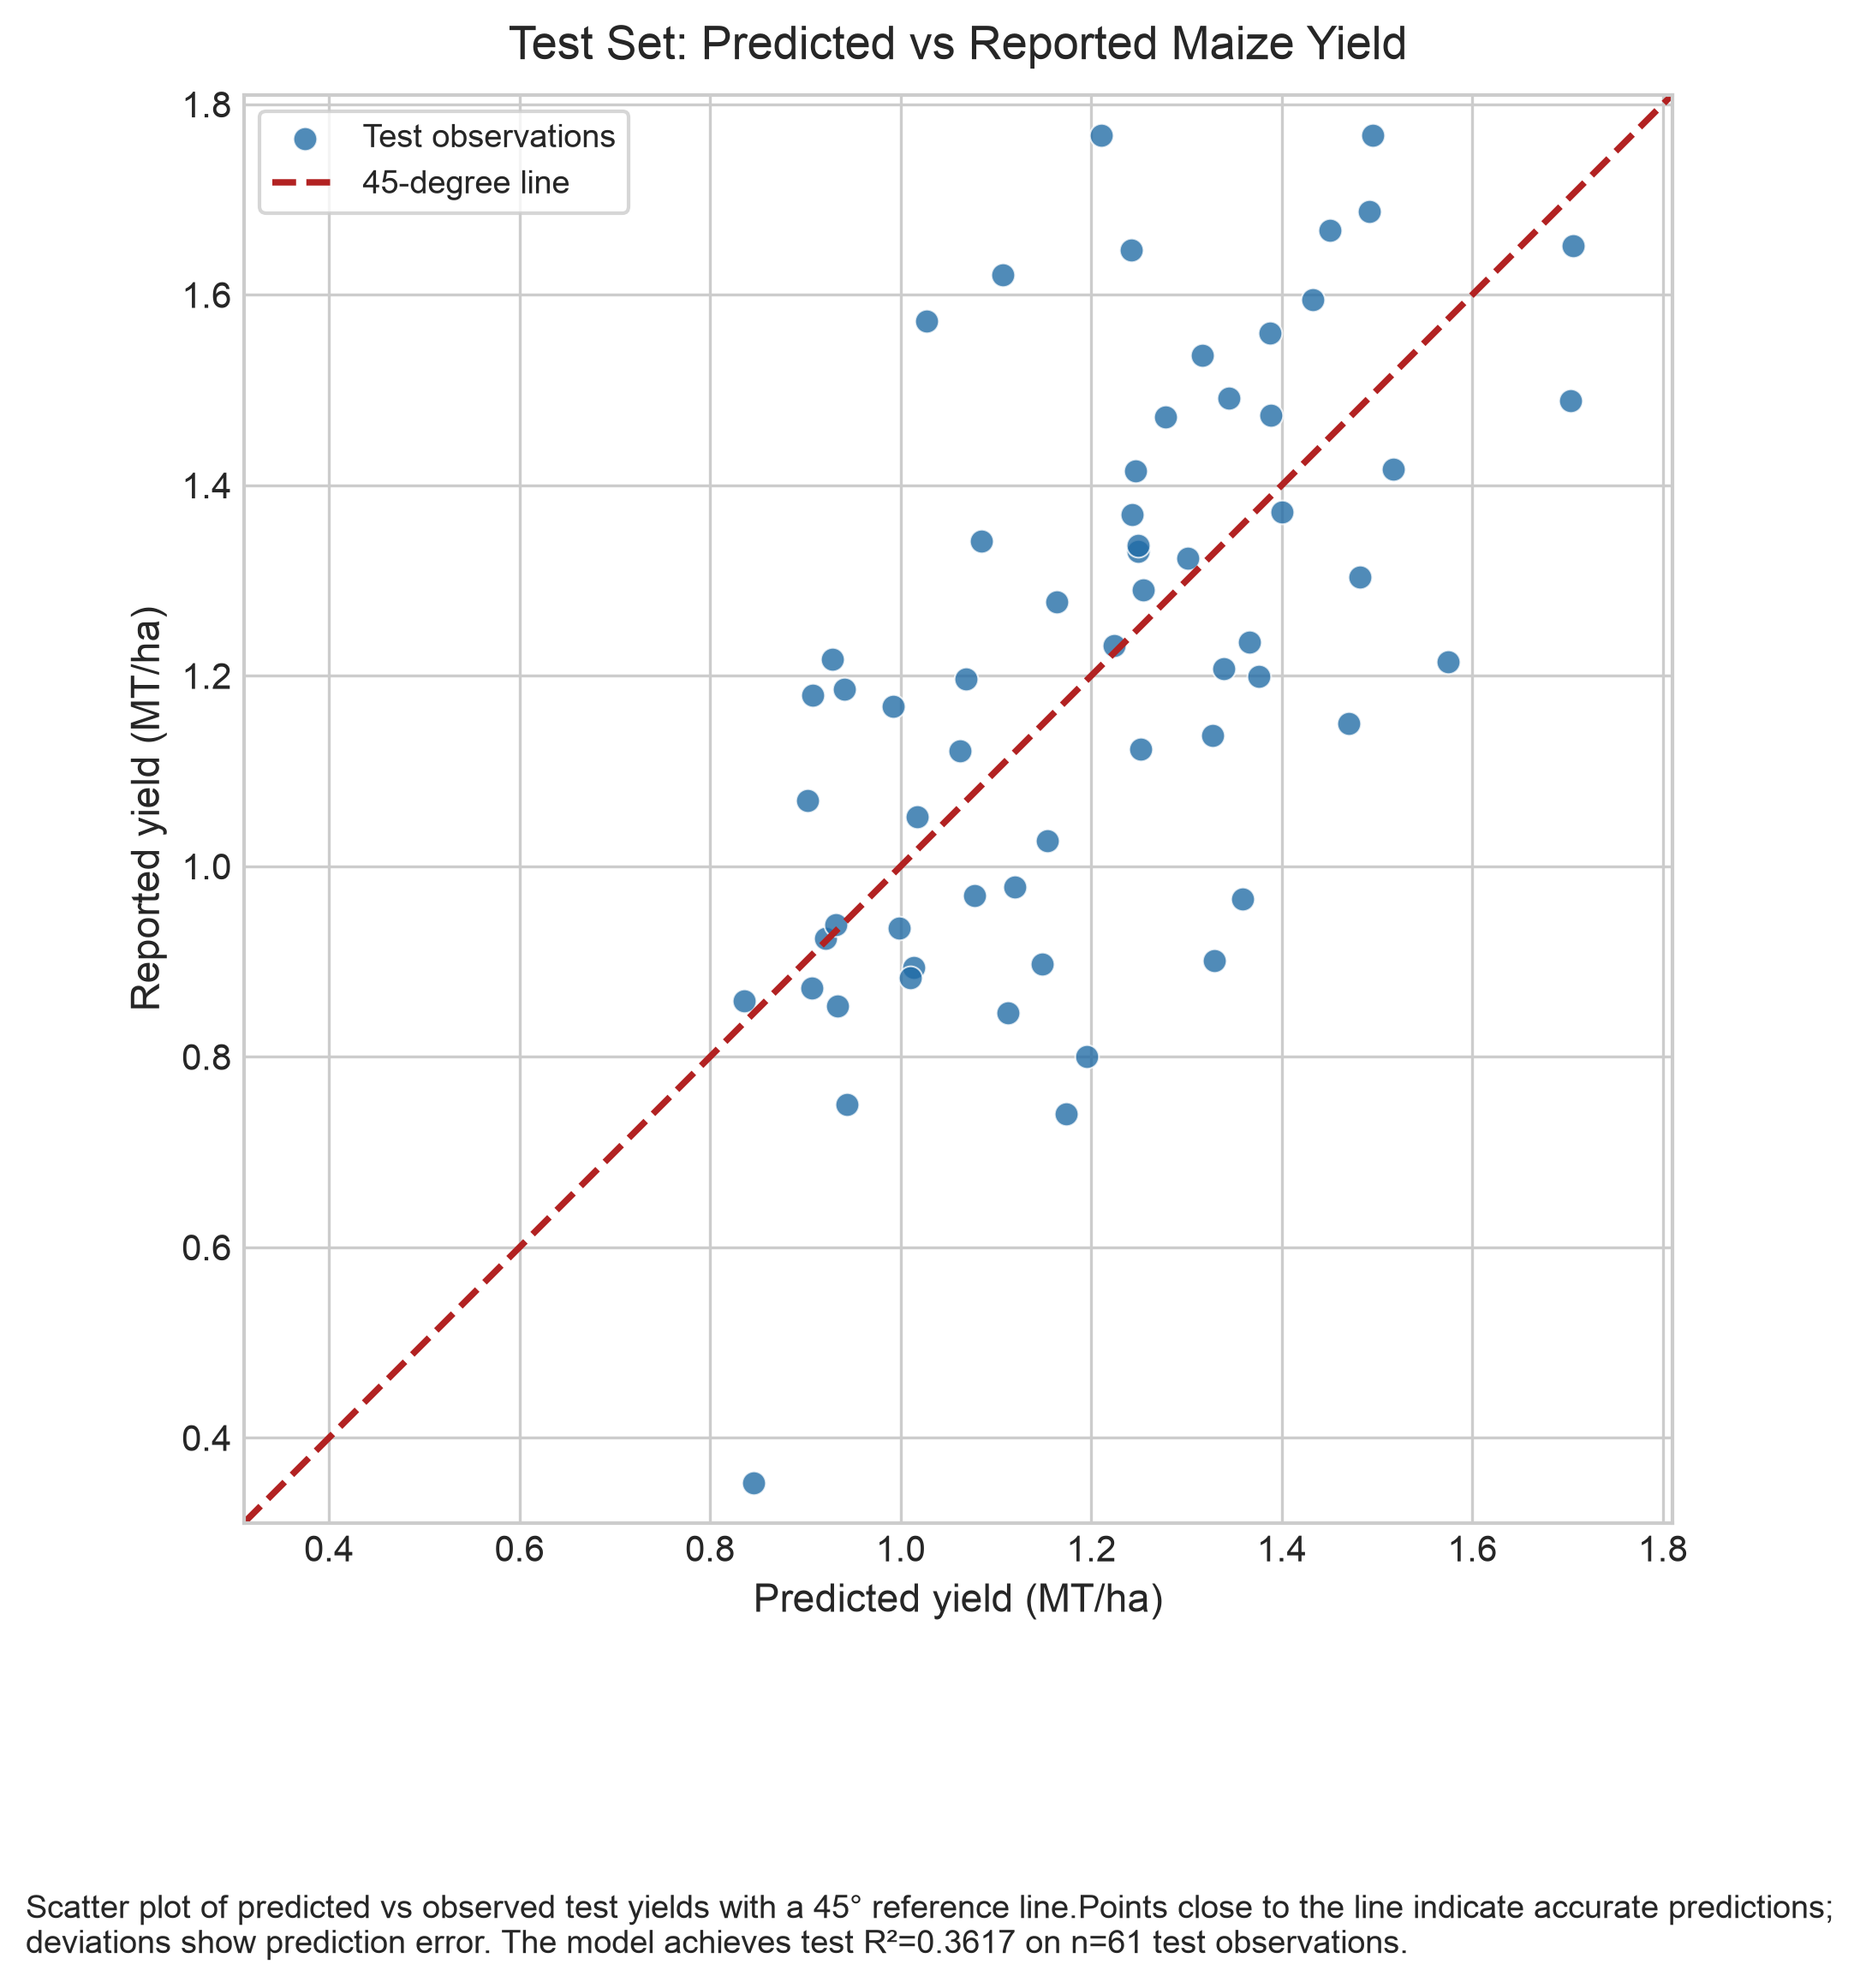

Saved publication plot to: outputs/test_predictions_vs_reported_yield.pdf
Final test R²: 0.3617
Test sample size (n): 61


In [30]:
# Publication-quality scatter plot: predicted vs observed yields on test set (Admin2 model)
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Recompute admin2 test predictions from the fitted admin2 model objects.
# This avoids variable collisions with later cells (e.g., admin1 section).
if "search" not in globals() or "X_test" not in globals() or "y_test" not in globals():
    raise RuntimeError("Run the Admin2 training cell first (Section 2) before plotting.")

y_pred_admin2 = search.predict(X_test)
y_true_admin2 = y_test.copy()

# If target is on log scale, convert both vectors back to reported yields (MT/ha).
if np.nanmax(np.abs(y_true_admin2)) < 10:
    y_test_reported = np.exp(y_true_admin2)
    y_pred_reported = np.exp(y_pred_admin2)
else:
    y_test_reported = np.asarray(y_true_admin2)
    y_pred_reported = np.asarray(y_pred_admin2)

# Final test-set diagnostics
n_test = len(y_test_reported)
final_test_r2 = r2_score(y_test_reported, y_pred_reported)

# Create output folder for publication figures
os.makedirs("outputs", exist_ok=True)
pdf_path = "outputs/test_predictions_vs_reported_yield.pdf"

# Figure style
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7.2, 7.0), dpi=300)

# Scatter points
ax.scatter(
    y_pred_reported,
    y_test_reported,
    s=44,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.5,
    color="#1f6aa5",
    label="Test observations"
)

# 45-degree reference line
xy_all = np.concatenate([np.asarray(y_pred_reported), np.asarray(y_test_reported)])
line_min = float(np.nanmin(xy_all))
line_max = float(np.nanmax(xy_all))
pad = 0.03 * (line_max - line_min if line_max > line_min else 1.0)
line_min -= pad
line_max += pad
ax.plot([line_min, line_max], [line_min, line_max], "--", color="#b22222", linewidth=1.8, label="45-degree line")

# Axes and labels
ax.set_xlim(line_min, line_max)
ax.set_ylim(line_min, line_max)
ax.set_xlabel("Predicted yield (MT/ha)", fontsize=11)
ax.set_ylabel("Reported yield (MT/ha)", fontsize=11)
ax.set_title("Test Set: Predicted vs Reported Maize Yield", fontsize=13, pad=10)
ax.legend(frameon=True, fontsize=9)
ax.set_aspect("equal", adjustable="box")

# Figure caption with required metrics
caption = (
    f"Scatter plot of predicted vs observed test yields with a 45° reference line."
    f"Points close to the line indicate accurate predictions; deviations show prediction error. "
    f"The model achieves test R²=0.3617 on n=61 test observations."
)
fig.text(0.02, -0.06, caption, ha="left", va="top", fontsize=9, wrap=True)

# Save as PDF (publication output)
plt.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
plt.show()

print(f"Saved publication plot to: {pdf_path}")
print(f"Final test R²: {final_test_r2:.4f}")
print(f"Test sample size (n): {n_test}")